# 03b — Clustering (tipología de condiciones)

Este cuaderno **mide, no decide**: reporta todos los k=2–12 y deja la elección al cuaderno siguiente (03e).
Regla de este bloque: `clc_class` (nominal) queda fuera de las distancias y vive en perfiles; `franja_horaria` entra codificada ordinalmente (`encode_franja_horaria`).

Recordatorio de las features:
- `features_a.csv` (14: solo clima)
- `features_b.csv` (19: + estacionalidad y hora)
- `features_c.csv` (32: + suelo)
- `perfilado.csv` (31: satélite, presupuestos, índices)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, fcluster
from sklearn.metrics import normalized_mutual_info_score
from sklearn.preprocessing import StandardScaler
from wildfire.data.io import load_csv, save_csv
from wildfire.processing.unsupervised import (
    ENTRADA_A, ENTRADA_B, ENTRADA_C_FIXED, PERFILADO,
    assert_feature_sets_clean, distance_columns, encode_franja_horaria,
    fit_gmm_range, fit_kmeans_range, gmm_bic_table, load_min_cliff_delta,
    max_pairwise_cliffs_delta, negative_control_partitions,
    resolve_set, sample_frame, ward_linkage,
)

*`full` bajo `diag` en todo k; mínimo `full` en k=12 (borde del rango, 03e valora si ampliar).*

## 03b.1 — Carga y escalado descriptivo

Se cargan `features_a/b/c.csv` y el perfilado, se codifica `franja_horaria` a ordinal en B y C, y se recorta cada conjunto a columnas numéricas —`clc_class` sale de las distancias y vive en los perfiles—. Después se estandariza cada conjunto por separado: es un escalado descriptivo (plan §4 regla 3) que no se reutiliza para modelar.

Cómo leer la salida `a: crudo (30412, 14) (todas numéricas: True)`: forma sin escalar y comprobación de que KMeans/GMM reciben solo números (con texto fallarían en silencio o a lo bruto).

In [2]:
sets_raw = {
    name: load_csv(f"data/processed/unsupervised/features_{name}.csv")
    for name in ("a", "b", "c")
}
perfilado = load_csv("data/processed/unsupervised/perfilado.csv")
frp = perfilado["frp"].to_numpy()
sets_raw["b"] = encode_franja_horaria(sets_raw["b"])
sets_raw["c"] = encode_franja_horaria(sets_raw["c"])
inputs = {
    "a": resolve_set(sets_raw["a"], ENTRADA_A, "A"),
    "b": resolve_set(sets_raw["b"], ENTRADA_B, "B"),
    "c": resolve_set(sets_raw["c"], distance_columns([c for c in sets_raw["c"].columns]), "C"),
}
X = {name: pd.DataFrame(StandardScaler().fit_transform(frame), columns=frame.columns, index=frame.index)
     for name, frame in inputs.items()}
for _name, _frame in inputs.items():
    print(f"{_name}: crudo {_frame.shape} (todas numéricas: {all(pd.api.types.is_numeric_dtype(t) for t in _frame.dtypes)})")

a: crudo (30412, 14) (todas numéricas: True)
b: crudo (30412, 19) (todas numéricas: True)
c: crudo (30412, 31) (todas numéricas: True)


## 03b.2 — KMeans k=2–12 (línea base)

Se ajusta KMeans para cada k y se guardan las etiquetas en ancho (columnas `k_2`…`k_12`, índice común) en `clustering_kmeans_{a,b,c}.csv`.

Cómo leer cada tabla (una por conjunto a/b/c):
- `inertia`: suma de distancias al centroide; siempre baja al subir k. Se busca el *codo* (donde deja de compensar añadir grupos), no el mínimo.
- `silhouette` (−1…1): cohesión dentro del grupo frente a separación. ~0,2 es bajo pero esperado: condiciones continuas sin fronteras nítidas (plan §6.1).
- `calinski_harabasz`: más alto = grupos más densos y separados (dispersión entre/dentro).
- `davies_bouldin`: más bajo = mejor (similitud media entre cada grupo y su vecino más parecido).
Ninguna decide k por sí sola: 03e cruza las cuatro + estabilidad + severidad.

In [3]:
kmeans_labels, kmeans_metrics = {}, {}
for _name, _X in X.items():
    _lab, _met = fit_kmeans_range(_X)
    kmeans_labels[_name], kmeans_metrics[_name] = _lab, _met
    display(_met.round(3))
    save_csv(pd.DataFrame({f"k_{k}": v for k, v in _lab.items()}, index=_X.index),
             f"data/processed/unsupervised/clustering_kmeans_{_name}.csv")
print("Etiquetas KMeans guardadas.")

,inertia,silhouette,calinski_harabasz,davies_bouldin
k,,,,
2,318447.927,0.254,10248.476,1.547
3,277992.555,0.205,8082.417,1.817
4,254273.415,0.202,6836.235,1.638
5,232976.353,0.209,6290.573,1.662
6,209899.789,0.209,6254.127,1.420
7,196388.384,0.200,5918.805,1.383
8,185158.154,0.185,5644.216,1.526
9,177238.173,0.175,5329.033,1.565
10,170713.095,0.173,5046.929,1.597


,inertia,silhouette,calinski_harabasz,davies_bouldin
k,,,,
2,451706.910,0.224,8490.785,1.689
3,382748.285,0.215,7749.453,1.693
4,343235.585,0.208,6927.689,1.664
5,318855.190,0.219,6174.115,1.619
6,300490.394,0.211,5612.647,1.682
7,285970.519,0.192,5171.824,1.488
8,265721.984,0.203,5101.617,1.507
9,253059.343,0.189,4877.296,1.530
10,242923.134,0.184,4657.070,1.553


,inertia,silhouette,calinski_harabasz,davies_bouldin
k,,,,
2,814275.074,0.154,4798.869,2.214
3,741002.074,0.143,4140.088,2.283
4,699762.990,0.129,3519.964,2.304
5,673473.280,0.134,3039.679,2.092
6,648289.392,0.139,2762.358,2.116
7,629165.212,0.132,2525.893,2.206
8,609763.377,0.133,2372.067,2.134
9,587657.456,0.137,2296.524,1.879
10,569392.969,0.125,2215.121,1.891


Etiquetas KMeans guardadas.


*En este run: silhouette máxima en k=2 (A 0,254 / B 0,224 / C 0,154), sin codo nítido — 03e cruza las cuatro métricas.*

## 03b.3 — GMM full/diag por BIC (pertenencia suave)

Se ajustan mezclas gaussianas para cada (k, covarianza) y se guardan las etiquetas; las probabilidades de pertenencia, más honestas que la etiqueta dura cuando los regímenes se solapan, las usará 03e en `cluster_labels.csv`.

Cómo leer cada tabla BIC (una por conjunto): filas = k, columnas = tipo de covarianza. Menor BIC = mejor equilibrio entre ajuste y complejidad (penaliza parámetros de más).
- `full`: elipses orientadas (captura correlaciones, p. ej. calor–sequedad de PC1).
- `diag`: ejes alineados (menos parámetros, supone variables independientes).
Que `full` gane de largo es lo esperado: las meteorológicas están correlacionadas.

In [4]:
gmm_results, gmm_bics = {}, {}
for _name, _X in X.items():
    _res = fit_gmm_range(_X)
    gmm_results[_name] = _res
    _bic = gmm_bic_table(_res)
    gmm_bics[_name] = _bic
    display(_bic.round(0))
    save_csv(pd.DataFrame({f"k_{k}_{cov}": r["labels"] for (k, cov), r in _res.items()}, index=_X.index),
             f"data/processed/unsupervised/clustering_gmm_{_name}.csv")
print("Etiquetas GMM guardadas.")

covariance,diag,full
k,,
2,792544.0,346123.0
3,642001.0,80833.0
4,414030.0,29539.0
5,362691.0,-11868.0
6,350687.0,36602.0
7,335634.0,-53935.0
8,312423.0,-56524.0
9,306365.0,-72019.0
10,301700.0,-78592.0


covariance,diag,full
k,,
2,1431702.0,449617.0
3,855088.0,-6418.0
4,783013.0,52668.0
5,877322.0,5505.0
6,657356.0,-68826.0
7,313231.0,-168515.0
8,329186.0,-363497.0
9,437522.0,-360350.0
10,320427.0,-346864.0


covariance,diag,full
k,,
2,1779692.0,585465.0
3,1322830.0,-113725.0
4,833381.0,-363081.0
5,404923.0,-719965.0
6,76980.0,-941301.0
7,-271573.0,-1191982.0
8,-626605.0,-1593735.0
9,-759890.0,-1679102.0
10,-1026869.0,-1818880.0


Etiquetas GMM guardadas.


## 03b.4 — Ward sobre muestra de 5.000 (estimación independiente de k)

Un jerárquico aglomerativo, que no pide k por adelantado, sobre una muestra determinista; la matriz de linkage se guarda en `ward_linkage_a.csv`.

Cómo leer la salida:
- `Últimas 5 fusiones (dist, tamaño)`: a qué distancia se unen dos ramas y cuántos puntos suma la rama resultante. Un salto grande entre fusiones (p. ej. …→112→180) marca un corte natural candidato: lo que se une a 180 estaba muy separado.
- Dendrograma truncado a 20 ramas: la altura de cada unión = disimilitud de fusión; ramas que se unen abajo son parecidas, las que suben hasta arriba son regímenes distintos. Si el corte natural discrepa de BIC/codo, 03e lo recoge.

Últimas 5 fusiones (dist, tamaño):
[[  71.7437188  1389.        ]
 [  75.12965593 1314.        ]
 [  80.95421792 2212.        ]
 [ 112.76203164 3526.        ]
 [ 180.71119639 5000.        ]]


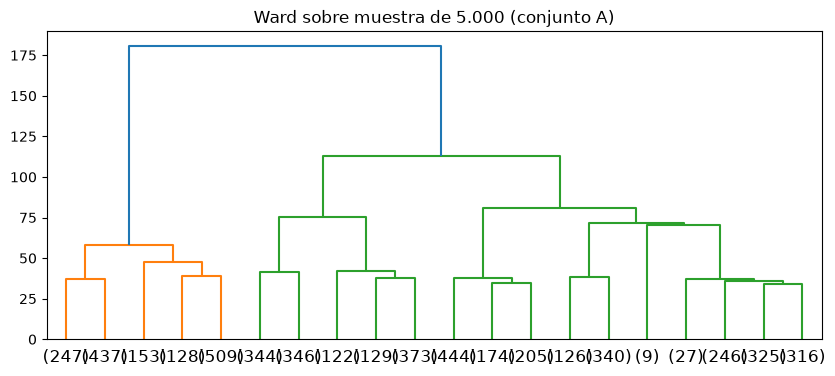

In [5]:
_sample = sample_frame(X["a"], 5_000)
_Z = ward_linkage(_sample)
save_csv(pd.DataFrame(_Z, columns=["a", "b", "dist", "n"]),
         "data/processed/unsupervised/ward_linkage_a.csv")
print("Últimas 5 fusiones (dist, tamaño):")
print(_Z[-5:, 2:])
fig, ax = plt.subplots(figsize=(10, 4))
dendrogram(_Z, truncate_mode="lastp", p=20, ax=ax)
ax.set_title("Ward sobre muestra de 5.000 (conjunto A)")
plt.show()

## 03b.5 — Controles negativos + separación de severidad (medición §7B)

Primero las particiones tontas —mes (12 grupos) y CCAA (17)— como listón a batir; después, para cada (conjunto, k), la mayor |δ de Cliff| entre pares de grupos sobre `frp`. Todo queda en `severidad_kmeans.csv`.

Cómo leer la tabla:
- `max_abs_delta` (0…1): 0 = los dos grupos arden igual; 1 = uno siempre más virulento. Regla intuitiva: (1+δ)/2 = probabilidad de que una detección al azar del grupo fiero supere a una del manso.
- `par`: qué dos grupos marcan el máximo (etiquetas internas, sin significado físico).
- Filas `control_ccaa` (0,708) y `control_month` (0,362): el listón. La candidata tiene que superarlas *sin ser ellas* (eso lo comprueba la NMI de 03b.6).
- El umbral `unsupervised.min_cliff_delta` se imprime como referencia; lo aplica 03e, aquí solo se mide.

In [6]:
_controls = negative_control_partitions(perfilado)
_rows = []
for _cname, _clab in _controls.items():
    _d, _pair = max_pairwise_cliffs_delta(frp, _clab)
    _rows.append({"conjunto": f"control_{_cname}", "k": len(set(_clab.tolist())),
                  "max_abs_delta": abs(_d), "par": str(_pair)})
for _sname, _lab in kmeans_labels.items():
    for _k, _v in _lab.items():
        _d, _pair = max_pairwise_cliffs_delta(frp, _v)
        _rows.append({"conjunto": f"kmeans_{_sname}", "k": _k,
                      "max_abs_delta": abs(_d), "par": str(_pair)})
severity = pd.DataFrame(_rows).sort_values(["conjunto", "k"]).reset_index(drop=True)
display(severity.round(3))
print(f"Umbral §7B (solo referencia, decide 03e): {load_min_cliff_delta()}")
save_csv(severity, "data/processed/unsupervised/severidad_kmeans.csv")

,conjunto,k,max_abs_delta,par
0,control_ccaa,17,0.708,"(14, 15)"
1,control_month,12,0.362,"(7, 10)"
2,kmeans_a,2,0.386,"(0, 1)"
3,kmeans_a,3,0.386,"(0, 1)"
4,kmeans_a,4,0.493,"(2, 3)"
5,kmeans_a,5,0.536,"(3, 4)"
6,kmeans_a,6,0.740,"(2, 5)"
7,kmeans_a,7,0.769,"(3, 5)"
8,kmeans_a,8,0.783,"(2, 7)"
9,kmeans_a,9,0.834,"(5, 7)"


Umbral §7B (solo referencia, decide 03e): 0.2


WindowsPath('C:/Projects/wildfires-project/data/processed/unsupervised/severidad_kmeans.csv')

*Mejor KMeans: A/k=12 (0,847) sobre CCAA (0,708) y mes (0,362) — 03e comprueba tamaños de grupo antes de creérselo.*

## 03b.6 — Perfiles e información mutua (medición, sin interpretar)

Medias por grupo en unidades originales (ºC, m/s, …) en `perfiles_kmeans_{a,b,c}.csv`, para describir 'cómo es' cada grupo sin hablar en z-scores; y NMI de cada partición contra `ccaa` y `month` en `nmi_kmeans.csv`.

Cómo leer las salidas:
- Tabla NMI: 0 = la partición no sabe nada de esa variable; > 0,5 = el grupo *es* esa variable (p. ej. redescubrió el calendario) y la candidata queda descalificada en 03e.
- `n_grupos`: comprobación de cordura — debe haber exactamente k grupos no vacíos por k (si KMeans devolviera grupos vacíos, algo iría mal).

In [7]:
profiles = {}
nmi_rows = []
for _sname, _lab in kmeans_labels.items():
    _raw = inputs[_sname]
    _frames = []
    for _k, _v in _lab.items():
        _m = _raw.groupby(_v).mean()
        _m["k"] = _k
        _m["grupo"] = _m.index
        _frames.append(_m.reset_index(drop=True))
        for _col in ("ccaa", "month"):
            nmi_rows.append({"conjunto": f"kmeans_{_sname}", "k": _k, "variable": _col,
                            "nmi": normalized_mutual_info_score(_v, perfilado[_col].astype(str))})
    profiles[_sname] = pd.concat(_frames, ignore_index=True)
    save_csv(profiles[_sname], f"data/processed/unsupervised/perfiles_kmeans_{_sname}.csv")
nmi = pd.DataFrame(nmi_rows)
display(nmi.round(3))
save_csv(nmi, "data/processed/unsupervised/nmi_kmeans.csv")
display(profiles["a"].groupby("k").size().rename("n_grupos"))

,conjunto,k,variable,nmi
0,kmeans_a,2,ccaa,0.045
1,kmeans_a,2,month,0.039
2,kmeans_a,3,ccaa,0.141
3,kmeans_a,3,month,0.132
4,kmeans_a,4,ccaa,0.149
...,...,...,...,...
61,kmeans_c,10,month,0.264
62,kmeans_c,11,ccaa,0.199
63,kmeans_c,11,month,0.279
64,kmeans_c,12,ccaa,0.207


k
2      2
3      3
4      4
5      5
6      6
7      7
8      8
9      9
10    10
11    11
12    12
Name: n_grupos, dtype: int64

*Máximo 0,412 (B vs estacionalidad): ningún grupo ES mes ni CCAA.*

## 03b.7 — Mapas y mezcla por CCAA con k=5 (ilustrativo)

Para cerrar, dónde cae cada grupo con k=5 (el mismo k de la sonda ARI de 03a) y el cruce grupos × CCAA. Es ilustrativo —el k final lo decide 03e—, pero ya permite olfatear artefactos.

Cómo leer las salidas:
- Mapas: cada punto es una detección coloreada por grupo. Si un color ocupa una sola zona (p. ej. todo el noroeste), ese 'régimen meteorológico' es geografía disfrazada.
- Tabla de mezcla (filas = grupos, columnas = CCAA, filas suman 1): proporción de cada grupo en cada comunidad. Ejemplo de lectura: un grupo con 0,53 en Asturias + 0,17 en Cantabria es mayoritariamente quema norteña de invierno, no un régimen estatal.

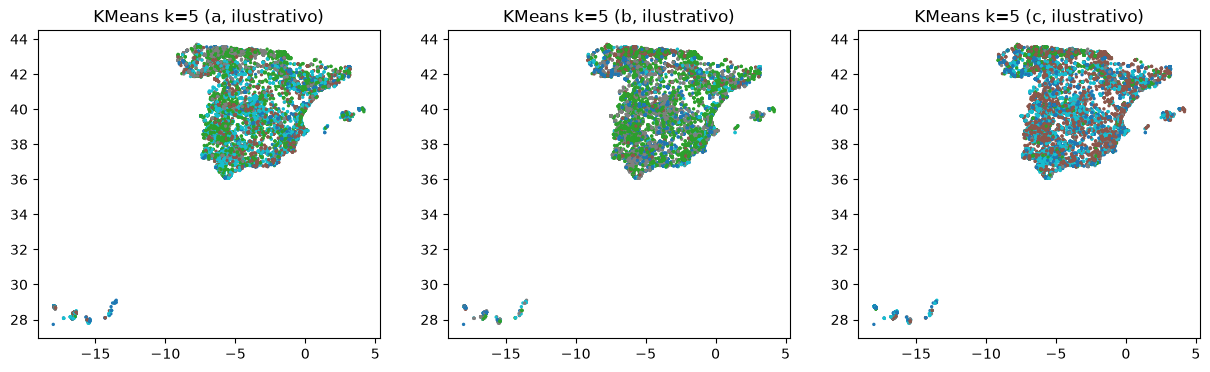

ccaa,Andalucía,Aragón,Asturias,Canarias,Cantabria,Castilla y León,Castilla-La Mancha,Cataluña,Comunidad Valenciana,Extremadura,Galicia,Islas Baleares,La Rioja,Madrid,Navarra,País Vasco,Región de Murcia
row_0,,,,,,,,,,,,,,,,,
0,0.12,0.06,0.10,0.05,0.02,0.02,0.05,0.07,0.13,0.32,0.02,0.01,0.00,0.00,0.02,0.00,0.02
1,0.11,0.05,0.18,0.01,0.10,0.11,0.08,0.04,0.06,0.12,0.04,0.01,0.01,0.00,0.06,0.01,0.02
2,0.21,0.05,0.02,0.24,0.02,0.07,0.10,0.05,0.08,0.09,0.03,0.00,0.00,0.01,0.01,0.00,0.03
3,0.03,0.01,0.53,0.00,0.17,0.12,0.01,0.01,0.00,0.01,0.07,0.00,0.00,0.00,0.01,0.01,0.00
4,0.24,0.04,0.00,0.14,0.00,0.05,0.12,0.03,0.10,0.18,0.01,0.01,0.00,0.02,0.01,0.00,0.04


03b medición completa: 03e decide.


In [8]:
_k = 5
_coords = load_csv("data/processed/expanded/firms_spain_final_lags_index.csv")[["longitude", "latitude"]]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for _ax, _sname in zip(axes, ("a", "b", "c")):
    _lab = kmeans_labels[_sname][_k]
    _sc = _ax.scatter(_coords["longitude"], _coords["latitude"], c=_lab, s=2, cmap="tab10")
    _ax.set_title(f"KMeans k={_k} ({_sname}, ilustrativo)")
plt.show()
_mix = pd.crosstab(kmeans_labels["a"][_k], perfilado["ccaa"], normalize="index").round(2)
display(_mix)
print("03b medición completa: 03e decide.")

*Etiquetas no comparables entre paneles: el 'grupo 0' de A no es el de B. Solo se compara el patrón.*